In [11]:
import numpy as np
import matplotlib.pyplot as plt
import slab2 as sg
from scipy.optimize import newton

plt.style.use('dark_background')
%matplotlib widget

# Setup Waveguide and input fields

In [47]:
B = sg.Slab(scale=1e-5, ns=[1, 1.44, 1], Ts=[6,1,6], wl=5.83e-06)
A = sg.Slab(scale=1e-5, Ts=[6.5, 1, 6, 1, 6.5],  ns=[1, 1.44, 1, 1.44, 1],
                 xrefs=[180, 40, 200, 40, 180], wl=5.83e-06)

In [48]:
b = 1.25
a = 1/ b**2
def f0(x):
    conds = [(x<-b), ((-b<=x)*(x<=b)), (x>b)]
    funcs = [0, lambda x: 1 - a * x**2, 0]
    return np.piecewise(x, conds, funcs)

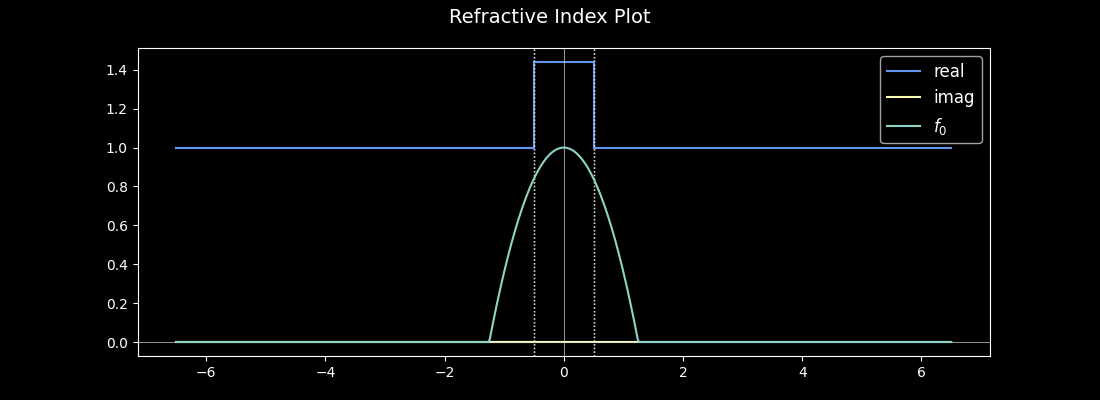

In [49]:
sg.plot_refractive_index(B);
sg.add_1d_plot(B, f0, label='$f_0$')

# Debugging Guided Mode coefficients

These are very hard to get using the standard transfer matrix method.  Can we do better somehow?

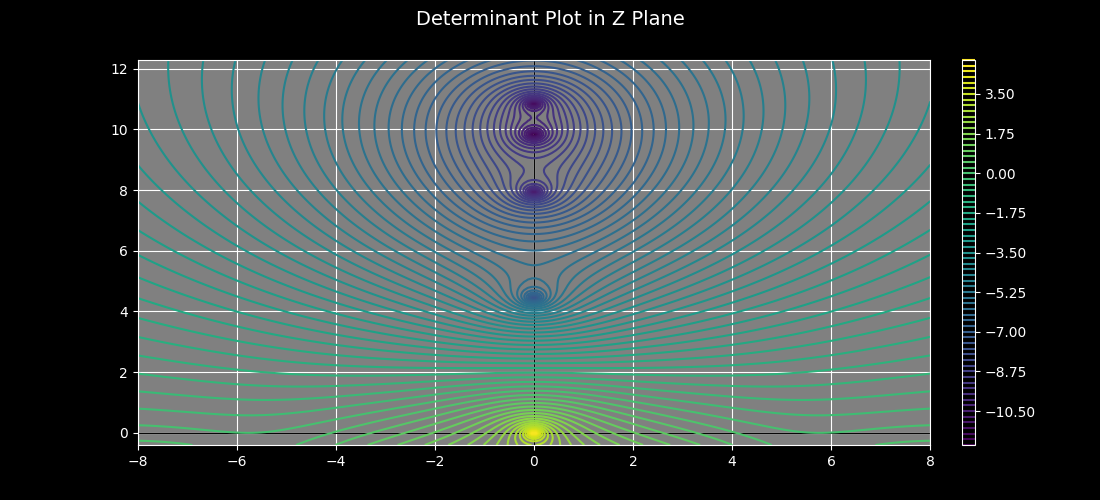

In [54]:
sg.eigenvalue_plot(B, -8, 8, -.4, 1.1 * B.Z_max_guided.imag);

In [55]:
B.get_guided_modes()
sg.plot_points(B.guided_prop_constants)

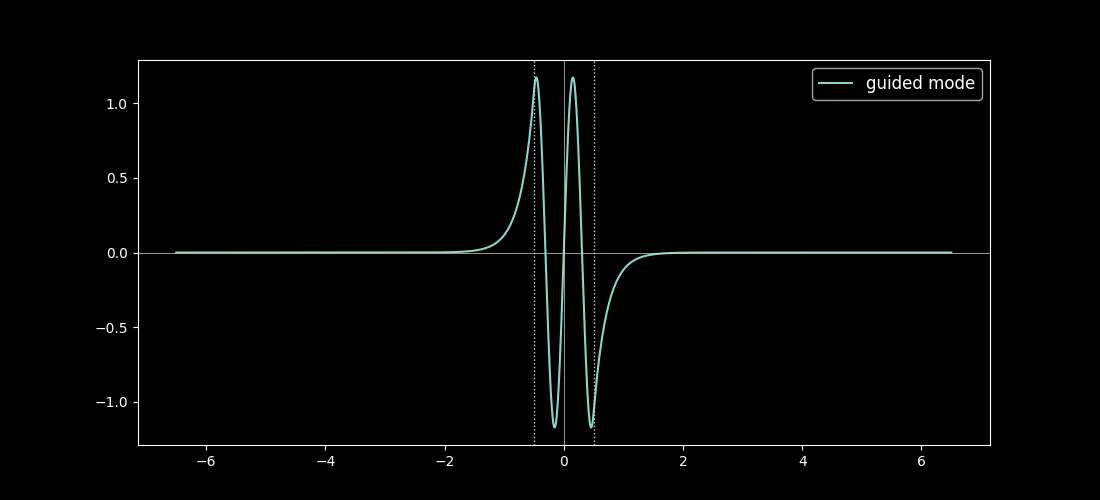

In [56]:
sg.plot_field_1d(B, B.guided_modes[-1], label='guided mode');


In [ ]:
xs = A.all_Xs
zs = np.linspace(0, 100, int(100*40/2))

In [ ]:
f0s = f0(xs)

In [ ]:
rad_ys_propagating = Prop(xs, zs)


In [ ]:
rad_ys_evanescent = Ev(xs, zs)


In [ ]:
# guided_ys = alpha * Fs1(xs, zs=zs)

In [ ]:
Xs, Zs = np.meshgrid(xs, zs)

In [ ]:
def get_trig_indices(mesh_array):
    '''Get triangle index list for three js mesh formation via indexed buffer geometry.'''
    if len(mesh_array.shape) <= 1:
        raise ValueError('Provide meshgrid array as input.')
    Nz, Nx = mesh_array.shape[0], mesh_array.shape[1]
    l_inds = Nx * Nz
    indices =  np.arange(0, l_inds).reshape((Nx, Nz)).T  # Note transpose
    fbases = indices[:Nz-1, :Nx-1].T.flatten()  # Note transpose and index switch due to transpose
    f1 = np.array([[i, i+Nz, i+1] for i in fbases], dtype=int)
    f2 = np.array([[i+1, i+Nz, i+Nz+1] for i in fbases], dtype=int)
    return np.concatenate((f1, f2))


def get_base_vertices(Xs, Zs):
    '''Get vertices of triangles with zero height (y component in three.js).'''
    if Xs.shape != Zs.shape:
        raise ValueError('Provide meshgrid arrays (ie Xs, Zs = np.meshgrid(xs,zs)) as inputs.')
    Base = np.array([Xs, np.zeros_like(Xs), Zs], dtype=float)
    L = Xs.shape[0] * Xs.shape[1]
    base_vertices = Base.T.reshape((L,3))
    return base_vertices


def create_height_array_from_complex(ys, Xs):
    '''Get data for height from complex ys input (needs to be formatted as list:
        [ys[0].real, ys[0].imag, ys[1].real, ys[1].imag, ... ].'''
    L = Xs.shape[0] * Xs.shape[1]
    Ys = np.array([ys.real, ys.imag], dtype=float)
    heights = Ys.T.reshape((L,2))
    return heights


def save_trig_indices_as_json(filepath, mesh_array):
    indices = get_trig_indices(mesh_array)
    with open(filepath + '.json', 'w') as outfile:
        json.dump(indices.flatten().tolist(), outfile, separators=(',', ':'),
                  sort_keys=True, indent=4)


def save_base_vertices_as_json(filepath, Xs, Zs):
    base_vertices = get_base_vertices(Xs, Zs)
    with open(filepath + '.json', 'w') as outfile:
        json.dump(base_vertices.flatten().tolist(), outfile, separators=(',', ':'),
                  sort_keys=True, indent=4)
        

def save_heights_as_json(filepath, ys, Xs):
    heights= create_height_array_from_complex(ys, Xs)
    with open(filepath + '.json', 'w') as outfile:
        json.dump(heights.flatten().tolist(), outfile, separators=(',', ':'),
                  sort_keys=True, indent=4)

def save_values_as_json(filepath, f0s):
    with open(filepath + '.json', 'w') as outfile:
        json.dump(f0s.tolist(), outfile, separators=(',', ':'),
                  sort_keys=True, indent=4)


In [ ]:
prefix='/home/pv/local/slab/apps/hollow_core/'

In [ ]:
save_trig_indices_as_json(prefix + 'trig_indices_new', Xs)

In [ ]:
save_base_vertices_as_json(prefix + 'base_vertices_new', Xs, Zs)

In [ ]:
# save_heights_as_json(prefix + 'guided_heights', guided_ys, Xs)

In [ ]:
save_heights_as_json(prefix + 'evanescent_heights', rad_ys_evanescent, Xs)

In [ ]:
save_heights_as_json(prefix + 'propagating_heights', rad_ys_propagating, Xs)

In [ ]:
save_values_as_json(prefix + 'f0s', f0s)

In [ ]:
save_values_as_json(prefix + 'x0s', xs)

In [ ]:
mode_type = 'leaky'
k_low = A.K_low

In [ ]:
plotlogf(A.determinant, .94*A.K_low, 1.0001*A.K_low, -.1, .1, field_type, mode_type, 
         figsize=(10,5),iref=400, rref=400, levels=200)

### Only even modes necessary

In [ ]:
beta1 = newton(A.determinant, 10.775, args=(field_type, mode_type)).conj()
beta2 = newton(A.determinant, 10.715, args=(field_type, mode_type))
beta3 = newton(A.determinant, 10.6, args=(field_type, mode_type))
beta4 = newton(A.determinant, 10.42, args=(field_type, mode_type))
beta5 = newton(A.determinant, 10.2, args=(field_type, mode_type))

betas = [beta1, beta2, beta3, beta4, beta5]
for beta in betas:
    plt.plot(beta.real, beta.imag, marker='o')


In [ ]:
Fs1 = A.fields(beta1, field_type=field_type, mode_type=mode_type, c0=-1)
Fs2 = A.fields(beta2, field_type=field_type, mode_type=mode_type, c0=-1)
Fs3 = A.fields(beta3, field_type=field_type, mode_type=mode_type, c0=-1)
Fs4 = A.fields(beta4, field_type=field_type, mode_type=mode_type, c0=-1)
Fs5 = A.fields(beta5, field_type=field_type, mode_type=mode_type, c0=-1)

Fs = [Fs1, Fs2, Fs3, Fs4, Fs5]

### Plotting leaky modes

#### 1D plots

In [ ]:
A.plot_field_1d(Fs1)
A.add_1d_plot(Fs2)
A.add_1d_plot(Fs3)
A.add_1d_plot(Fs4)
A.add_1d_plot(Fs5)


### Build "full" leaky field

At this point this is just to get an idea of combining leaky modes.  Scaling should be done via contour integration.

In [ ]:
from scipy.integrate import quad
cfs = np.zeros(len(Fs))
alphas = np.zeros(len(Fs))
for i,F in enumerate(Fs):
    integrand = lambda x: F(x) * F(x).conjugate()
    cfs[i] = quad(integrand, A.Rhos[2], A.Rhos[3], complex_func=True)[0].real
    integrand = lambda x: f0(x) * F(x).conjugate()
    alphas[i] = quad(integrand, A.Rhos[2], A.Rhos[3], complex_func=True)[0].real

# Note: Not clear that this is correct process for scaling leaky fields

In [ ]:
Full_leaky = lambda x, z: sum([Fs[i](x,z) * alphas[i]/cfs[i] for i in range(len(Fs))])

### 2D plots

In [ ]:
xs = np.linspace(-20,20,1000)

In [ ]:
fig, ax = A.plot_field_2d(Full_leaky, xs=xs, zmin=0, zmax=100, zref=2000, colorbar=False)
plt.axis('equal')